# 03 · Consensus-Loop Runs

Exercises the `consensus` decision rules on the two-pendulum setup from
`example.yaml` (truth = damped-driven oscillator, interpreters = cosine).

> **Note on the shipped driver.** While building these tests I found that
> `metascience_simulation.run_consensus_compare` crashes in two situations
> (details in the final cell), so this notebook drives the consensus API
> directly and runs a small, controlled loop. That keeps the test
> deterministic and also documents the driver bugs for a follow-up fix.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import mstest_utils as mu          # shared helpers (lives in metascience/python/)
import interpret, cosmology, consensus

np.random.seed(0)
plt.rcParams['figure.figsize'] = (8, 4.5)

## 1. One consensus step, inspected

Build two interpreters (as the pipeline does), then call `tension_metric()`
and `render_judgment()` and read off every decision the consensus made.

In [2]:
_, iA, _ = mu.run_fit(truth_name='DampedDrivenOscillatorCosmology', interp_name='CosineCosmology',
                      times='times_A.txt', noise=0.03, seed=110)
_, iB, _ = mu.run_fit(truth_name='DampedDrivenOscillatorCosmology', interp_name='CosineCosmology',
                      times='times_B.txt', noise=0.1,
                      true_systematics=np.array([0.0007,0,0,0,0]), seed=110)

con = consensus.ImpatientConsensus(interpretations=[iA, iB], patience=5, chi2_dof_threshold=1.25)
con.tension_metric()
con.render_judgment(number_of_tries=0)

print('chi2/dof  A, B        :', round(mu.chi2_per_dof(iA),2), round(mu.chi2_per_dof(iB),2))
print('tension metric (tm)   :', np.round(con.tm, 2))
print('is_tension            :', con.is_tension)
print('systematics_judgment  :', con.systematics_judgment, '  (which interpreters must add systematics)')
print('cosmology_judgment    :', con.cosmology_judgment, '  (change the cosmology model?)')
print('consensus parameter   :', con.consensus_cosmological_parameters)

Initial guess:[0.5 2.  0.  0. ]
best fit:[ 1.06309238  0.46106078 -3.56997003 -0.01934474]


Initial guess:[0.5 2.  0.  0. ]
best fit:[ 0.89446313  0.41471666 -0.95916224  0.08458401]


tension metric threshold: 10.567384899086996
chi2/dof  A, B        : 15.08 1.93
tension metric (tm)   : [  0.   208.22]
is_tension            : True
systematics_judgment  : [True, True]   (which interpreters must add systematics)
cosmology_judgment    : False   (change the cosmology model?)
consensus parameter   : [0.89446313]


## 2. Controlled refinement loop

The real loop responds to `systematics_judgment` by giving an interpreter more
systematics freedom. Here we do exactly that for experiment A by hand, adding
Laguerre terms one at a time, and watch χ²/dof and the A–B tension respond.

Initial guess:[0.5 2.  0.  0. ]
best fit:[ 1.06309238  0.46106078 -3.56997003 -0.01934474]


tension metric threshold: 10.567384899086996
Initial guess:[0.5 2.  0.  0.  0. ]


best fit:[ 1.06434055  0.46140799 -3.57452631  0.33577691 -0.35549424]


tension metric threshold: 10.567384899086994
Initial guess:[0.5 2.  0.  0.  0.  0. ]


best fit:[  1.06505113   0.4618512   -3.57770286  11.37913834 -22.47425384
  11.11110838]


tension metric threshold: 10.567384899086992
Initial guess:[0.5 2.  0.  0.  0.  0.  0. ]


... (2 outputs left out)

best fit:[ 1.06841259e+00  4.63413737e-01 -3.58992262e+00 -1.19209534e+04
  4.77655859e+04 -7.18444740e+04  4.80762914e+04 -1.20765041e+04]


tension metric threshold: 10.567384899086994
Initial guess:[0.5 2.  0.  0.  0.  0.  0.  0.  0. ]


best fit:[ 1.06574230e+00  4.62976884e-01 -3.58059483e+00 -1.37349261e+05
  6.76989460e+05 -1.33557165e+06  1.31820431e+06 -6.50906929e+05
  1.28634020e+05]


tension metric threshold: 10.567384899086992
n_terms=1: chi2/dof(A)= 15.08  tension=  208.22
n_terms=2: chi2/dof(A)= 15.07  tension=  205.93
n_terms=3: chi2/dof(A)= 15.05  tension=  207.13
n_terms=4: chi2/dof(A)= 15.05  tension=  198.05
n_terms=5: chi2/dof(A)= 14.95  tension=  204.57
n_terms=6: chi2/dof(A)= 14.94  tension=  158.91


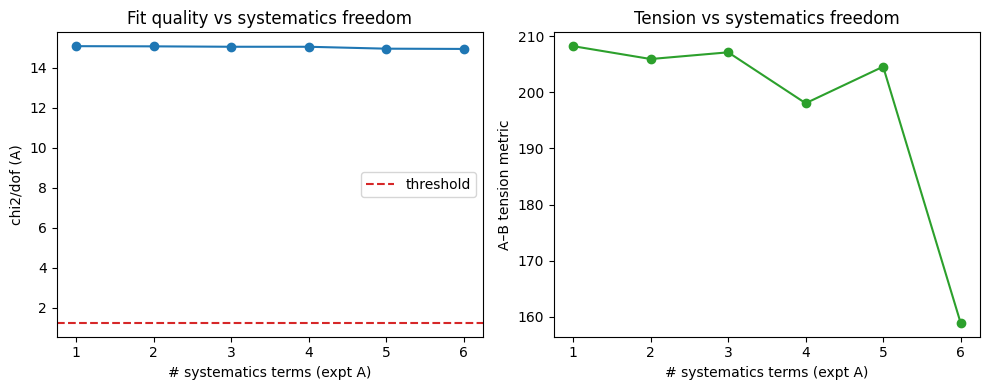

In [3]:
n_terms = [1, 2, 3, 4, 5, 6]
c2d_hist, tm_hist, w_hist = [], [], []
for n in n_terms:
    _, iA_n, _ = mu.run_fit(truth_name='DampedDrivenOscillatorCosmology', interp_name='CosineCosmology',
                            times='times_A.txt', noise=0.03,
                            starting_systematics=np.zeros(n), seed=110)
    con = consensus.ImpatientConsensus(interpretations=[iA_n, iB], patience=5, chi2_dof_threshold=1.25)
    con.tension_metric()
    c2d_hist.append(mu.chi2_per_dof(iA_n))
    tm_hist.append(con.tm[1])
    w_hist.append(iA_n.best_fit_cosmological_parameters[0])

fig, (a0, a1) = plt.subplots(1, 2, figsize=(10, 4))
a0.plot(n_terms, c2d_hist, 'o-'); a0.axhline(1.25, color='C3', ls='--', label='threshold')
a0.set_xlabel('# systematics terms (expt A)'); a0.set_ylabel('chi2/dof (A)'); a0.legend()
a0.set_title('Fit quality vs systematics freedom')
a1.plot(n_terms, tm_hist, 'o-', color='C2')
a1.set_xlabel('# systematics terms (expt A)'); a1.set_ylabel('A–B tension metric')
a1.set_title('Tension vs systematics freedom')
plt.tight_layout()
for n,c,t in zip(n_terms,c2d_hist,tm_hist):
    print(f'n_terms={n}: chi2/dof(A)={c:6.2f}  tension={t:8.2f}')

## 3. Driver bugs found (for a follow-up fix)

`run_consensus_compare` in `metascience_simulation.py` fails in two ways,
independent of the covariance fixes:

1. **`result.data_chi2 = [thing.chi2 for thing in interpreters]`** — when a run
   ends right after a cosmology change (or hits `max_iter`), the interpreters
   were just re-created and never re-fit, so they have no `.chi2`
   (`AttributeError`). It is `max_iter`-dependent, which makes it look
   intermittent.
2. **`patience=None` rules** (`ShiftThatParadigmConsensus`,
   `UnderestimatedErrorConsensus`): the loop evaluates
   `np.max(systematics_iter) > this_consensus.patience`, i.e. `float > None`,
   which raises `TypeError` in Python 3.

A third, quieter issue: the driver mutates the caller's `starting_systematics`
list in place, so running several consensus rules in one process contaminates
later runs (pass a deep copy per run). Happy to patch these too.